# Spread mean-reversion portfolio and the baseline network

A prices-only portfolio that fades the Brent − WTI and heating oil − gasoil spreads, built like the SG Trend replication. Its weekly position change, the spread flow $f_{m,t}$, is then added to the Insight 177 network's nowcast of the change in Managed Money (MM), $\Delta MM_{m,t}$.

**Observations** (weekly, to 2026-08-25).

- Rule Sharpe ratio, 2011–2025: Brent − WTI −0.33, heating oil − gasoil 1.29. The second is not tradable: gasoil settles about three hours before heating oil, and the daily spread P&L has autocorrelation −0.44.
- Baseline network, six markets, 2017–2025: $R^2$ = 44.90%, as in `nn_carry_volatility.ipynb`. With the spread flow: 46.25%.
- The gain is in WTI: 40.19% to 45.03%, positive in 8 of 9 years. Brent −0.03, heating oil −0.33, gasoil −0.24 points.
- $\rho$(NN error, $f$) is negative: WTI −0.37 and Brent −0.25 over 2017–2025, WTI −0.65 in May–Aug 2026. MM trades against the mean-reversion rule.
- WTI stays unexplained in the war: $R^2$ = −102.22% to −86.03% in Mar–Apr 2026, −82.88% to −71.79% in May–Aug 2026.

Helpers: [`src/spread.py`](src/spread.py), [`src/commodity_trend.py`](src/commodity_trend.py), [`src/sg_cta.py`](src/sg_cta.py).

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'working_ideas' else Path.cwd()
DATA = REPO_ROOT / 'working_ideas' / 'data_required'
PAPER_DATA = REPO_ROOT / 'paper_replication' / 'data_required'
sys.path[:0] = [str(REPO_ROOT / 'paper_replication' / 'src'), str(REPO_ROOT / 'working_ideas' / 'src')]

import torch
from paper_replication.config import ReplicationConfig
import commodity_trend as ct
import sg_cta as sg
import spread as sp

OUTPUT = REPO_ROOT / 'paper_replication' / 'outputs' / 'spread_mean_reversion'
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
START = '2011-07-12'      # first week with a year of ICE positions
END = '2026-08-25'        # last report week of the energy Managed Money data
WAR_START = '2026-03-03'  # first report week of the war
PERIODS = {'2011–2019': (START, '2019-12-31'), '2020–2025': ('2020', '2025'), 'Mar–Apr 2026': ('2026-03-01', '2026-04-30'),
           'May–Aug 2026': ('2026-05-01', END)}
COLORS = {'Brent-WTI': '#277f8e', 'Heating oil-Gasoil': '#b7782c', 'war': '#f3e6d8'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Portfolio construction

Prices only, as the SG Trend replication. Helpers: [`src/spread.py`](src/spread.py).

1. **Spread.** Long leg A, short leg B, equal barrels, both in the delivery month leg A holds, rolled five trading days before leg A's last trade date. Brent − WTI: 1 : 1 contracts. Heating oil − gasoil: 1 : 1.342 (a gasoil contract is 100 tonnes, 745 barrels).
2. **Signal.** $C_t$ is the cumulated weekly spread P&L in USD per barrel, $\sigma_t$ its weekly volatility over 90 trading days. For $n\in\{4,13,26\}$ weeks,

$$z_t(n)=\frac{C_t-\frac1n\sum_{k=0}^{n-1}C_{t-k}}{\sigma_t\sqrt{(n-1)(2n-1)/(6n)}},\qquad u_t=-\frac13\sum_n\text{clip}\big(z_t(n),-1,1\big).$$

The denominator is the standard deviation of the numerator under a random walk, so each $z$ has unit variance before the cap, as Kestner's signal.

3. **Position.** $N_t=u_t\cdot\text{risk}/(\sigma_t\sqrt{52}\cdot 1000)$, in units of 1,000 barrels of spread. Risk is \$100m of annual volatility at $|u|=1$, an arbitrary constant: no index calibrates it.
4. **Flow.** $f_{A,t}=\Delta N_t$ and $f_{B,t}=-\Delta N_t$, converted to contracts.

,Brent-WTI,Heating oil-Gasoil
"Spread, USD/bbl, 2011–2019",7.78,2.16
"Spread, USD/bbl, 2020–2025",4.02,6.67
"Spread, USD/bbl, Mar–Apr 2026",8.84,6.04
"Spread, USD/bbl, May–Aug 2026",6.05,12.23
"Weekly vol, USD/bbl, 2011–2019",1.12,1.12
"Weekly vol, USD/bbl, 2020–2025",0.50,1.86
"Weekly vol, USD/bbl, Mar–Apr 2026",1.33,3.54
"Weekly vol, USD/bbl, May–Aug 2026",2.14,4.77
Daily P&L autocorrelation,0.03,-0.44
Weekly P&L autocorrelation,-0.02,-0.17


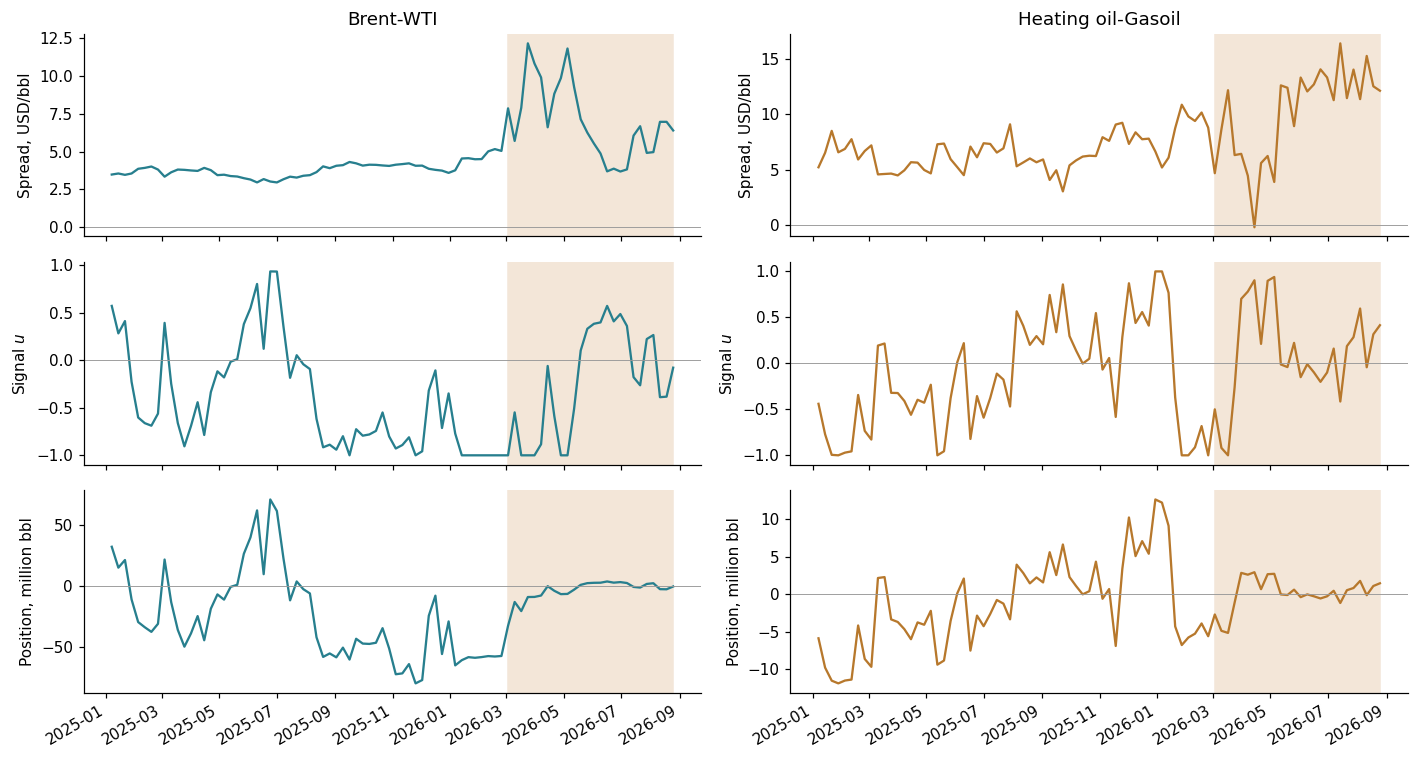

In [2]:
T = ct.trend_panel(DATA, PAPER_DATA, END)
generic, meta = sp.load_energy(PAPER_DATA)
panels = {pair: sp.spread_panel(generic, meta, pair, T.d_mm.index) for pair in sp.PAIRS}

rows = {}
for pair, P in panels.items():
    a, b = P.legs
    rule_pnl = P.units.shift(1) * P.pnl * 1000 / 1e6        # USD million a week
    sharpe = lambda start, end: rule_pnl[start:end].mean() / rule_pnl[start:end].std() * np.sqrt(52)
    row = {f'Spread, USD/bbl, {p}': P.level[s:e].mean() for p, (s, e) in PERIODS.items()}
    row |= {f'Weekly vol, USD/bbl, {p}': P.vol[s:e].mean() for p, (s, e) in PERIODS.items()}
    row |= {'Daily P&L autocorrelation': P.daily['pnl'][START:END].autocorr(1), 'Weekly P&L autocorrelation': P.pnl[START:END].autocorr(1),
            'Weeks with all three signals capped, %': 100 * (P.signals[START:END].abs() >= sp.CAP).all(axis=1).mean(),
            'Rule Sharpe ratio, 2011–2025': sharpe(START, '2025'), 'Rule Sharpe ratio, Mar–Aug 2026': sharpe('2026-03-01', END),
            'ρ(spread flow, trend flow), leg A': P.flow[a][START:END].corr(T.d_pos[a][START:END]),
            'ρ(spread flow, trend flow), leg B': P.flow[b][START:END].corr(T.d_pos[b][START:END])}
    rows[pair] = row
construction = pd.DataFrame(rows)
display(construction.round(2))

fig, axes = plt.subplots(3, 2, figsize=(13, 7), sharex=True)
for column, (pair, P) in enumerate(panels.items()):
    for ax, series, label in zip(axes[:, column], [P.level, P.signal, P.units / 1000],
                                 ['Spread, USD/bbl', 'Signal $u$', 'Position, million bbl']):
        ax.plot(series['2025':END], color=COLORS[pair])
        ax.axvspan(pd.Timestamp(WAR_START), pd.Timestamp(END), color=COLORS['war'], zorder=0)
        ax.axhline(0, color='0.6', lw=0.6)
        ax.set_ylabel(label)
    axes[0, column].set_title(pair)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT / 'spread_signal_position.png', dpi=160)
plt.show()

**Observed.**

| | Brent − WTI | Heating oil − gasoil |
|---|---|---|
| Spread, USD/bbl, 2011–2019 / 2020–2025 / May–Aug 2026 | 7.78 / 4.02 / 6.05 | 2.16 / 6.67 / 12.23 |
| Weekly vol, USD/bbl, same periods | 1.12 / 0.50 / 2.14 | 1.12 / 1.86 / 4.77 |
| P&L autocorrelation, daily / weekly | 0.03 / −0.02 | −0.44 / −0.17 |
| Rule Sharpe ratio, 2011–2025 / Mar–Aug 2026 | −0.33 / −1.24 | 1.29 / 1.58 |
| $\rho$(spread flow, trend flow), leg A / leg B | −0.09 / −0.01 | −0.20 / 0.02 |

- All three signals are capped in 12.8% and 5.2% of weeks.
- $N\propto1/\sigma$, so the rule trades less in the war. Mean $|\Delta N|$ a week, 2025 to March–August 2026: 18.0 to 4.1 million barrels in Brent − WTI, 3.3 to 1.3 in heating oil − gasoil.
- Gasoil settles in London about three hours before heating oil in New York. The negative autocorrelation and the Sharpe ratio of heating oil − gasoil are consistent with this timing gap alone.

## 2. Baseline network with the spread flow

The Insight 177 network is refitted weekly from 2015 to August 2026, with the same windows, warm starts and seed as the replication (`sg.run_decomposition`). Its nowcast is kept fixed and its error is regressed on the spread flow of the same week:

$$\widehat{\Delta MM}^{corr}_{m,t}=\widehat{\Delta MM}^{NN}_{m,t}+s_{m,t}\,\gamma_{m,t}\,\frac{f_{m,t}}{s_{m,t}},$$

with $s$ the lagged position scale and $\gamma_{m,t}$ a ridge fit (penalty 0.1) per market on the previous 104 out-of-sample errors, as the carry correction in `nn_carry_volatility.ipynb`. $f=0$ in RBOB and natural gas. $\gamma>0$: MM trades with the mean-reversion rule.

In [3]:
config = ReplicationConfig(data_dir=PAPER_DATA, basis='futures_only', train_weeks=104, seed=7, evaluation_end='2026-12-31')
panel, _ = sg.load_weekly_data(config)
decomposition, _ = sg.run_decomposition(panel, config)
nn = decomposition.merge(panel[sg.KEYS + ['actual_change', 'mm_std_lag', 'panel_date']], on=sg.KEYS, validate='one_to_one')
nn['predicted_change'] = nn['mm_std_lag'] * (nn['trend_cur'] - nn['trend_prev'])
nn['normalized_error'] = (nn['actual_change'] - nn['predicted_change']) / nn['mm_std_lag']

flow = pd.concat([P.flow for P in panels.values()], axis=1).reindex(columns=sg.MARKETS, fill_value=0.0)
nn = nn.merge(flow.stack().rename('spread_flow').rename_axis(sg.KEYS).reset_index(), on=sg.KEYS, how='left')
nn['spread_flow'] = nn['spread_flow'] / nn['mm_std_lag']
corrected, gamma = sg.rolling_ridge(nn, ['spread_flow'], 'normalized_error', 'predicted_change', pooled=False)
corrected = corrected.rename(columns={'prediction': 'corrected_change'})
gamma.index = pd.MultiIndex.from_tuples(gamma.index, names=sg.KEYS)

In [4]:
NN_PERIODS = {'2017–2025': ('2017-01-01', '2025-12-31'), 'Mar–Apr 2026': ('2026-03-01', '2026-04-30'), 'May–Aug 2026': ('2026-05-01', END)}
SPREAD_MARKETS = ['BRENT', 'WTI', 'HEATOIL', 'GASOIL']
rows = {}
for period, (start, end) in NN_PERIODS.items():
    sample = sg.common_sample(corrected, start, end)
    groups = {ct.NAMES[m]: sample[sample['market'] == m] for m in SPREAD_MARKETS} | {'Six markets': sample}
    for name, d in groups.items():
        one = name != 'Six markets'
        rows[period, name] = {'NN': sg.score(d)['R² (%)'], 'NN + spread flow': sg.score(d, 'corrected_change')['R² (%)'],
                              'ρ(NN error, flow)': d['normalized_error'].corr(d['spread_flow']) if one else np.nan,
                              'Mean γ': gamma['spread_flow'].xs(d['market'].iloc[0], level='market').loc[start:end].mean() if one else np.nan,
                              'Market-weeks': len(d)}
nn_table = pd.DataFrame(rows).T
nn_table.insert(2, 'Gain, pp', nn_table['NN + spread flow'] - nn_table['NN'])
display(nn_table.round(2))

sample = sg.common_sample(corrected, '2017-01-01', END)
gain = lambda d: sg.score(d, 'corrected_change')['R² (%)'] - sg.score(d)['R² (%)']
groups = {ct.NAMES[m]: sample[sample['market'] == m] for m in SPREAD_MARKETS} | {'Six markets': sample}
by_year = pd.DataFrame({name: d.groupby(d['panel_date'].dt.year).apply(gain, include_groups=False) for name, d in groups.items()})
print('R² gain from the spread flow by year, percentage points (2026: January to August)')
display(by_year.T.round(1))

NN  NN + spread flow  Gain, pp  \
2017–2025    ICE Brent         50.17             50.14     -0.03   
             CME WTI           40.19             45.03      4.84   
             CME Heating oil   34.96             34.64     -0.33   
             ICE Gasoil        47.38             47.14     -0.24   
             Six markets       44.90             46.25      1.35   
Mar–Apr 2026 ICE Brent          7.63             12.16      4.54   
             CME WTI         -102.22            -86.03     16.19   
             CME Heating oil -117.15           -111.32      5.83   
             ICE Gasoil        -4.60            -19.85    -15.25   
             Six markets       -3.79              0.39      4.18   
May–Aug 2026 ICE Brent         71.37             71.93      0.55   
             CME WTI          -82.88            -71.79     11.10   
             CME Heating oil    6.91              6.99      0.07   
             ICE Gasoil      -264.67           -265.96     -1.29   
             Six markets       43.46             44.79      1.33   

                              ρ(NN error, flow)  Mean γ  Market-weeks  
2017–2025    ICE Brent                    -0.25   -0.06         470.0  
             CME WTI                      -0.37   -0.07         470.0  
             CME Heating oil              -0.07   -0.02         470.0  
             ICE Gasoil                   -0.05   -0.01         470.0  
             Six markets                    NaN     NaN        2820.0  
Mar–Apr 2026 ICE Brent                    -0.42   -0.10           9.0  
             CME WTI                      -0.30   -0.15           9.0  
             CME Heating oil              -0.26   -0.01           9.0  
             ICE Gasoil                    0.56   -0.05           9.0  
             Six markets                    NaN     NaN          54.0  
May–Aug 2026 ICE Brent                    -0.40   -0.06          17.0  
             CME WTI                      -0.65   -0.14          17.0  
             CME Heating oil              -0.09   -0.00          17.0  
             ICE Gasoil                   -0.06   -0.03          17.0  
             Six markets                    NaN     NaN         102.0

R² gain from the spread flow by year, percentage points (2026: January to August)


panel_date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
ICE Brent,-14.5,-0.1,-0.1,4.2,-3.2,1.3,6.3,3.8,-3.2,1.5
CME WTI,1.8,4.7,0.7,-4.0,5.3,7.8,11.8,5.3,18.4,-4.1
CME Heating oil,1.3,-2.2,1.0,-1.1,2.4,-0.2,-3.9,-0.1,-0.5,-2.0
ICE Gasoil,-0.9,0.5,-1.6,-1.8,0.3,-0.4,-0.8,0.3,1.1,-2.2
Six markets,-2.5,1.1,0.1,0.3,0.2,2.4,6.4,3.0,1.6,0.4


**Observed.** $R^2$, network alone to network with the spread flow.

| | 2017–2025 | Mar–Apr 2026 ($n=9$) | May–Aug 2026 ($n=17$) |
|---|---|---|---|
| WTI | 40.19% to 45.03% | −102.22% to −86.03% | −82.88% to −71.79% |
| Brent | 50.17% to 50.14% | 7.63% to 12.16% | 71.37% to 71.93% |
| Heating oil | 34.96% to 34.64% | −117.15% to −111.32% | 6.91% to 6.99% |
| Gasoil | 47.38% to 47.14% | −4.60% to −19.85% | −264.67% to −265.96% |
| Six markets | 44.90% to 46.25% | −3.79% to 0.39% | 43.46% to 44.79% |

- Sign: $\rho$(NN error, $f$) = −0.37 in WTI and −0.25 in Brent over 2017–2025, −0.65 and −0.40 in May–Aug 2026. Mean $\gamma<0$ in all four markets. In weeks when the rule buys Brent and sells WTI, MM buys more WTI and less Brent than the network predicts.
- WTI gain by year, 2017–2025: 1.8, 4.7, 0.7, −4.0, 5.3, 7.8, 11.8, 5.3, 18.4 points. January–August 2026: −4.1.
- Brent gain by year: −14.5 (2017) to 6.3 (2023).
- No test of the gains is run.

## Not yet run

1. $\Delta MM^A-\Delta MM^B$ against the spread flow, next to the difference of the two trend flows.
2. A test of the gains (Clark-West, as in `leadlag_network.ipynb`), and the signal inside the network instead of as a correction.
3. The rule with the sign reversed (spread momentum), since $\gamma<0$.
4. Heating oil − gasoil on prices taken at the same time of day; crack spreads.

## Save results

In [5]:
for pair, P in panels.items():
    name = pair.lower().replace(' ', '_').replace('-', '_')
    (pd.DataFrame({'level': P.level, 'pnl': P.pnl, 'vol': P.vol, 'signal': P.signal, 'units': P.units,
                   'signal_flow': P.signal_flow, 'sizing_flow': P.sizing_flow}).join(P.flow.add_prefix('flow_'))
     .loc[START:END].to_csv(OUTPUT / f'{name}_panel.csv'))
construction.to_csv(OUTPUT / 'construction.csv')
corrected.to_csv(OUTPUT / 'nn_with_spread_flow.csv', index=False)
nn_table.to_csv(OUTPUT / 'nn_r2.csv')
by_year.to_csv(OUTPUT / 'nn_gain_by_year.csv')

## References

- Sun, W-Y., Bouchouev, I. and Fattouh, B. (2026), [Momentum Trading and Managed Money Positioning in Energy](https://www.oxfordenergy.org/wpcms/wp-content/uploads/2026/03/Insight-177-Money-Positioning-in-Energy.pdf), OIES Insight 177, for the network.
- Sun, W-Y., Bouchouev, I. and Fattouh, B. (2026), *Shifting Oil Market Positioning During the Strait of Hormuz Crisis*, OIES Energy Comment, October (`references/`).
- Kestner, L. N. (2020), *Replicating CTA Positioning: An Improved Method*, [SSRN 3674828](https://ssrn.com/abstract=3674828), for the capped, volatility-scaled signal and the sizing.